# 07 · Ablation studies (RQ5): which components actually matter?

An ablation changes **one** factor and keeps everything else fixed, then measures the change in accuracy. For S1 every ablation uses one reference model per fusion level: low (A1a: curves → PCA → LR), mid (A2: 120 features → SVM), high (A3: per-sensor LR → stacking). Each is evaluated with 5 × 5 repeated stratified CV (Experiment A's main table uses 10 × 5, so the *full* rows can differ slightly).

| ID | Question |
|---|---|
| AB1 | Which sensors matter? (leave one sensor out; single sensor only) |
| AB2 | How much of the 300-s recording is needed? |
| AB3 | Which signal representation works best, and does the pre-exposure baseline drive accuracy? |
| AB4 | Which hand-crafted feature types matter? |
| AB5 / AB6 | Which combiner / classifier family? (from Experiments A and C) |
| AB7 | How optimistic is leave-one-out compared with repeated 5-fold CV? |
| AB8 | Does the amount of SmellNet data or any harmonisation step change Experiment B? |
| AB9 | Which CQI attribute group carries the signal? |
| AB10 | Does sliding-window augmentation help the CNN? |

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30); pd.set_option('display.precision', 3)
R = ROOT / 'results'; F = R / 'figures'; A = R / 'ablations'
def show(p, w=650):
    p = Path(p)
    display(Image(filename=str(p), width=w)) if p.exists() else print('missing figure:', p.name)
def table(p, **kw):
    p = Path(p)
    return pd.read_csv(p, **kw) if p.exists() else print('missing table:', p.name)

## AB1: sensors
`delta_vs_full` is the change in accuracy compared with using all 8 sensors.

In [2]:
t = table(A / 'AB1_sensors.csv')
t.pivot_table(index='setting', columns='variant', values='accuracy_mean').round(3)

variant,A1a|LR,A1a|SVM,A2|LR,A2|SVM,A3|LR|mean,A3|LR|stacking
setting,,,,,,
full,0.917,0.914,0.852,0.866,0.769,0.810
only_SP-12A,0.666,0.648,0.610,0.621,0.610,0.679
only_SP-31,0.634,0.752,0.676,0.710,0.676,0.717
only_SP-AQ3,0.766,0.824,0.638,0.793,0.638,0.734
only_ST-31,0.738,0.717,0.693,0.721,0.693,0.690
only_TGS-800,0.810,0.817,0.697,0.855,0.697,0.755
only_TGS-813,0.597,0.652,0.590,0.545,0.590,0.534
only_TGS-823,0.731,0.766,0.683,0.766,0.683,0.717
only_TGS-842,0.693,0.748,0.686,0.755,0.686,0.659


## AB2: signal duration

In [3]:
t = table(A / 'AB2_duration.csv')
t.pivot_table(index='setting', columns='variant', values='accuracy_mean').round(3)

variant,A1a|LR,A1a|SVM,A2|LR,A2|SVM,A3|LR|mean,A3|LR|stacking
setting,,,,,,
first_120s,0.886,0.869,0.841,0.893,0.734,0.848
first_180s,0.893,0.897,0.838,0.852,0.724,0.807
first_30s,0.855,0.841,0.697,0.624,0.507,0.603
first_60s,0.828,0.838,0.807,0.828,0.717,0.766
full,0.917,0.914,0.852,0.866,0.769,0.810


## AB3: signal representation
R = raw resistance, G = conductance, R/R0 and G/G0 divide by the pre-exposure baseline (first 20 s), z = per-recording z-score; *diff25* applies SmellNet-style differencing x(t) − x(t−25). If accuracy falls sharply once the baseline is removed, the classifier was relying on the baseline level, which is measured before the coffee arrives.

In [4]:
t = table(A / 'AB3_representation.csv')
t.pivot_table(index='setting', columns='variant', values='accuracy_mean').round(3)

variant,A1a|LR,A1a|SVM,A2|LR,A2|SVM,A3|LR|mean,A3|LR|stacking
setting,,,,,,
G_diff25,0.724,0.779,0.762,0.772,0.831,0.793
RR0_diff25,0.766,0.807,0.828,0.779,0.786,0.841
full,0.917,0.914,0.852,0.866,0.769,0.810
rep_GG0,0.734,0.697,0.679,0.697,0.707,0.617
rep_R,0.897,0.921,0.869,0.872,0.772,0.841
rep_RR0,0.752,0.721,0.745,0.686,0.741,0.700
rep_z,0.779,0.797,0.872,0.859,0.738,0.769


## AB4: feature types (mid and high level)

In [5]:
t = table(A / 'AB4_features.csv')
t.pivot_table(index='setting', columns='variant', values='accuracy_mean').round(3)

variant,A2|LR,A2|SVM,A3|LR|mean,A3|LR|stacking
setting,,,,
full,0.852,0.866,0.769,0.810
no_auc,0.841,0.862,0.766,0.807
no_baseline,0.848,0.872,0.779,0.807
no_extrema,0.834,0.883,0.766,0.793
no_fft,0.855,0.869,0.779,0.797
no_final,0.841,0.866,0.759,0.783
no_moments,0.838,0.876,0.769,0.807
no_relative,0.848,0.876,0.772,0.803
no_slope,0.862,0.872,0.769,0.848


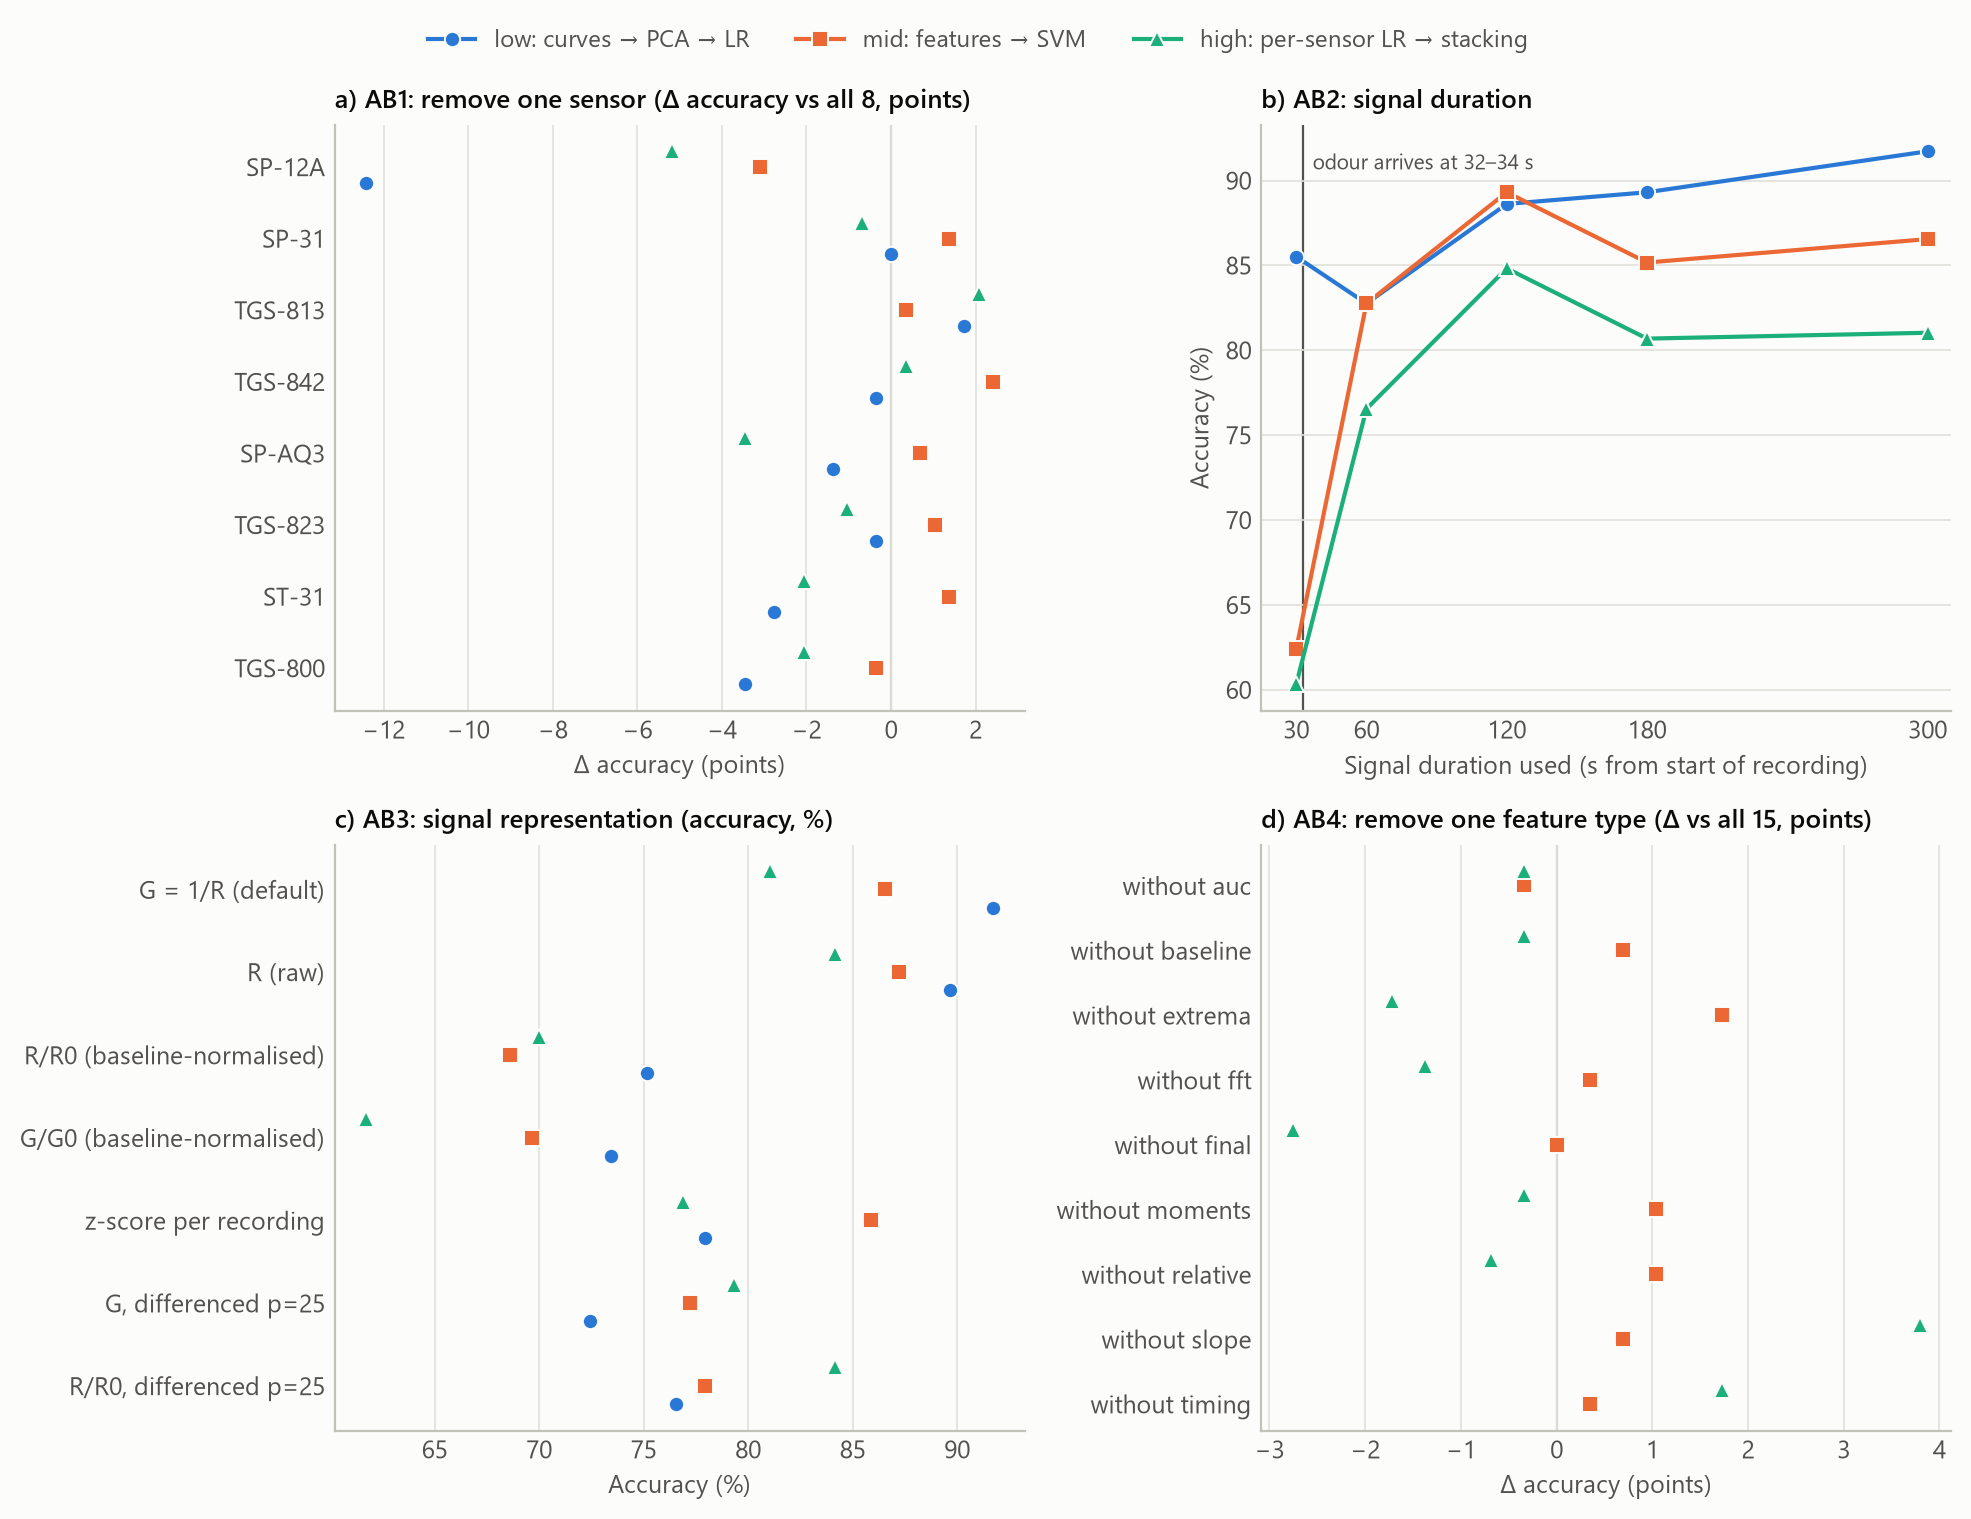

In [6]:
show(R.parent / 'article' / 'figures' / 'fig6_s1_ablations.png', 900)

## AB5 / AB6: combiners and classifier families

In [7]:
display(table(A / 'AB5_combiners_S1.csv')); display(table(A / 'AB6_classifier_family_S1.csv'))

,base,combiner,scheme,accuracy_mean,accuracy_std,macro_f1_mean
0,LR,vote,loo,0.776,0.000,0.753
1,LR,mean,loo,0.776,0.000,0.751
2,LR,weighted,loo,0.759,0.000,0.737
3,LR,stacking,loo,0.793,0.000,0.741
4,SVM,vote,loo,0.845,0.000,0.804
5,SVM,mean,loo,0.845,0.000,0.804
6,SVM,weighted,loo,0.828,0.000,0.784
7,SVM,stacking,loo,0.862,0.000,0.806
8,LR,vote,rskf5,0.752,0.038,0.730
9,LR,mean,rskf5,0.766,0.020,0.743


,level,classifier,scheme,accuracy_mean,accuracy_std,macro_f1_mean
0,A1a,LR,loo,0.931,0.000,0.907
1,A1a,SVM,loo,0.948,0.000,0.935
2,A1a,RF,loo,0.828,0.000,0.802
3,A1a,kNN,loo,0.845,0.000,0.830
4,A1a,MLP,loo,0.845,0.000,0.816
5,A2,LR,loo,0.879,0.000,0.859
6,A2,SVM,loo,0.897,0.000,0.857
7,A2,RF,loo,0.828,0.000,0.810
8,A2,kNN,loo,0.845,0.000,0.830
9,A2,MLP,loo,0.810,0.000,0.764


## AB7: leave-one-out vs repeated 5-fold
`loo_minus_rskf` > 0 means LOO reports a higher accuracy than repeated 5-fold CV for the same pipeline.

In [8]:
t = table(A / 'AB7_validation_scheme.csv')
t.sort_values('loo_minus_rskf', ascending=False)

,source,variant,loo,rskf5,loo_minus_rskf
7,baseline,dG-rel|center|sgd,0.833,0.791,4.195e-02
18,expA,A1b|CNN+win,0.931,0.891,3.966e-02
15,expA,A1a|SVM,0.948,0.910,3.793e-02
19,expA,A2|LR,0.879,0.847,3.276e-02
22,expA,A2|SVM,0.897,0.867,2.931e-02
17,expA,A1b|CNN,0.914,0.888,2.586e-02
23,expA,A2|kNN,0.845,0.819,2.586e-02
26,expA,A3|LR|vote,0.776,0.752,2.414e-02
29,expA,A3|SVM|stacking,0.862,0.843,1.897e-02
30,expA,A3|SVM|vote,0.845,0.828,1.724e-02


## AB8: SmellNet amount and harmonisation (Experiment B)

In [9]:
table(A / 'AB8_s2_gain_by_setting.csv')

,setting,B2|LR,B2|MLP64,B2|RF,S1only|LR,S1only|MLP64,S1only|RF,gain_LR,gain_RF,gain_MLP64
0,diff25,0.650,0.667,0.733,0.662,0.641,0.738,-0.012,-0.005,0.026
1,first_120s,0.621,0.707,0.603,0.679,0.719,0.662,-0.059,-0.059,-0.012
2,first_180s,0.700,0.750,0.667,0.729,0.769,0.693,-0.029,-0.026,-0.019
3,first_60s,0.619,0.591,0.655,0.655,0.633,0.688,-0.036,-0.033,-0.041
4,full,0.612,0.640,0.721,0.734,0.736,0.772,-0.122,-0.052,-0.097
5,no_common_length,0.634,0.660,0.719,0.734,0.736,0.772,-0.100,-0.053,-0.076
6,no_polarity(R),0.498,0.574,0.629,0.734,0.736,0.691,-0.236,-0.062,-0.162
7,norm_none,0.334,0.500,0.684,0.712,0.793,0.778,-0.378,-0.093,-0.293
8,norm_ratio,0.400,0.567,0.679,0.712,0.793,0.778,-0.312,-0.098,-0.226
9,s2_frac_10,0.598,0.655,0.657,0.734,0.736,0.772,-0.136,-0.116,-0.081


## AB10: sliding-window augmentation for the 1D-CNN

In [10]:
table(A / 'AB10_window_augmentation.csv')

,exp,variant,scheme,n_repeats,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std,rep,epochs,window,stride
0,expA_cnn,A1b|CNN,loo,1,0.914,0.000,0.876,0.000,0.883,0.000,G,150,NaN,NaN
1,expA_cnn,A1b|CNN,rskf5,10,0.888,0.032,0.872,0.030,0.867,0.035,G,150,NaN,NaN
2,expA_cnn_win,A1b|CNN+win,loo,1,0.931,0.000,0.910,0.000,0.915,0.000,G,60,250.0,10.0
3,expA_cnn_win,A1b|CNN+win,rskf5,10,0.891,0.022,0.863,0.024,0.867,0.026,G,60,250.0,10.0
